# Analysis

Python is the default kernel. An R kernel is fine if that is the language you can explain. `CHECKLIST.md` is the list that counts. The ticks on the lab page do not.

The held-out score, in the units of the decision, is computed in this notebook. The reason slide in `presentation.qmd` has to agree with it. The risk slide is the risk of the action, not this score.


## Setup

Import what you use and set the random seed. Pin those packages in `requirements.txt` and the interpreter in `.python-version`, or use `renv.lock` for R. When a result depends on the draw, record the seed in `decisions.md`. Before fitting, check each file in `data/` against the SHA-256 in `data/README.md`.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mtg

SEED = 0
np.random.seed(SEED)

# check the raw files against the SHA-256 in data/README.md
mtg.verify_files()
print("data files verified")

data files verified


In [2]:
# read only connection to the duckdb file
con = mtg.connect()

## Question

One sentence, then the quantity with units and a time window. Save the layer diagram, data to model to prediction to decision, as `fig/layers.png`.

![Layer diagram](fig/layers.png)


**What average mana value, number of lands and number of creatures should a two-colour Bloomburrow (BLB) Premier Draft deck have to win the most games?**

What we measure: a deck's win rate (games won / games played), reported as wins per 100 games. We score the decision as the extra wins per 100 games from following the model's advice compared to the baseline of always playing 17 lands. The data is best-of-1 games played from 30 Jul 2024 to 3 Sep 2024: 526,475 games and 106,900 decks after keeping only two-colour decks with no splash.

We fit a logistic regression two ways (statsmodels and our own gradient descent) and compare it to a baseline that predicts the average win rate for every deck.

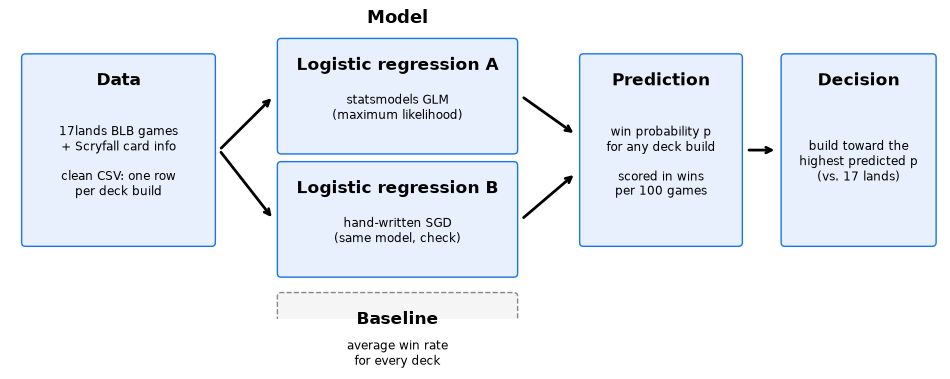

In [3]:
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(12, 4))
ax.set_xlim(0, 12)
ax.set_ylim(0, 4)
ax.axis("off")

def box(x, y, w, h, title, text, face="#e8f0fe", edge="#1a73e8", dashed=False):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.05",
                                facecolor=face, edgecolor=edge,
                                linestyle="--" if dashed else "-"))
    ax.text(x + w / 2, y + h - 0.3, title, ha="center", va="center",
            fontsize=12, fontweight="bold")
    ax.text(x + w / 2, y + (h - 0.3) / 2, text, ha="center", va="center", fontsize=8.5)

def arrow(x1, y1, x2, y2):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle="->", lw=2))

box(0.2, 1.0, 2.4, 2.4, "Data", "17lands BLB games\n+ Scryfall card info\n\nclean CSV: one row\nper deck build")

# two ways of fitting the same model, plus the baseline
box(3.5, 2.2, 3.0, 1.4, "Logistic regression A", "statsmodels GLM\n(maximum likelihood)")
box(3.5, 0.6, 3.0, 1.4, "Logistic regression B", "hand-written SGD\n(same model, check)")
box(3.5, -0.9, 3.0, 1.2, "Baseline", "average win rate\nfor every deck",
    face="#f5f5f5", edge="#888888", dashed=True)
ax.text(5.0, 3.85, "Model", ha="center", fontsize=13, fontweight="bold")

box(7.4, 1.0, 2.0, 2.4, "Prediction", "win probability p\nfor any deck build\n\nscored in wins\nper 100 games")

box(10.0, 1.0, 1.9, 2.4, "Decision", "build toward the\nhighest predicted p\n(vs. 17 lands)")

arrow(2.7, 2.2, 3.4, 2.9)
arrow(2.7, 2.2, 3.4, 1.3)
arrow(2.7, 2.2, 3.4, -0.3)
arrow(6.6, 2.9, 7.3, 2.4)
arrow(6.6, 1.3, 7.3, 1.9)
arrow(9.5, 2.2, 9.9, 2.2)

fig.savefig("fig/layers.png", dpi=200, bbox_inches="tight")
plt.show()

## Data

Download the release into this folder, with `OWNER/REPO` your fork:

```bash
gh release download data --dir data --repo OWNER/REPO
```

If the terms do not let you republish the files, there is no release: run the download command in `data/README.md` instead. The upload commands are in `data/README.md` too. Read the files from `data/`. Show one plot of the raw data and one table of summary statistics before any model. Save the plot under `fig/`.


In [4]:
from models.common import load_decks

decks = load_decks()
decks["win_rate"] = decks.wins / decks.games

# date range of the raw games
con.sql("SELECT min(game_time) AS first_game, max(game_time) AS last_game FROM games").show()

# totals after cleaning (two-colour, no splash)
print("decks:", len(decks), "| drafts:", decks.draft_id.nunique(), "| games:", decks.games.sum())

cols = ["avg_mana_value", "num_creatures", "num_lands", "win_rate"]
summary = decks[cols].agg(["mean", "std", "min", "max"]).T.round(3)
summary

┌─────────────────────┬─────────────────────┐
│     first_game      │      last_game      │
│      timestamp      │      timestamp      │
├─────────────────────┼─────────────────────┤
│ 2024-07-30 15:41:04 │ 2024-09-03 23:59:55 │
└─────────────────────┴─────────────────────┘

decks: 106900 | drafts: 90671 | games: 526475


,mean,std,min,max
avg_mana_value,2.809,0.291,1.68,4.174
num_creatures,14.777,2.164,2.00,23.000
num_lands,16.743,0.484,8.00,20.000
win_rate,0.480,0.287,0.00,1.000


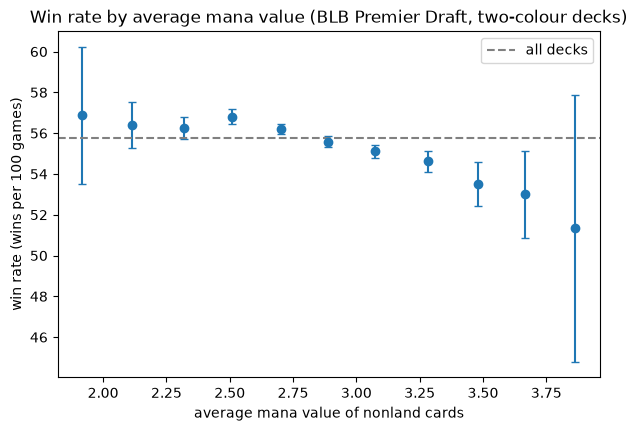

In [5]:
# group decks into bins of 0.2 average mana value
decks["m_bin"] = pd.cut(decks.avg_mana_value, bins=np.arange(1.0, 5.01, 0.2))

# wins, games and number of decks in each bin
g = decks.groupby("m_bin", observed=True).agg(
    wins=("wins", "sum"), games=("games", "sum"), n_decks=("wins", "size"),
    mid=("avg_mana_value", "mean"))
g = g[g.n_decks >= 30]  # bins with only a few decks are mostly noise

g["rate"] = g.wins / g.games
g["se"] = np.sqrt(g.rate * (1 - g.rate) / g.games)  # standard error

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.errorbar(g.mid, g.rate * 100, yerr=g.se * 100 * 1.96, fmt="o", capsize=3)
ax.axhline(100 * decks.wins.sum() / decks.games.sum(), ls="--", color="gray", label="all decks")
ax.set_xlabel("average mana value of nonland cards")
ax.set_ylabel("win rate (wins per 100 games)")
ax.set_title("Win rate by average mana value (BLB Premier Draft, two-colour decks)")
ax.legend()
fig.savefig("fig/winrate_by_mana_value.png", dpi=200, bbox_inches="tight")
plt.show()

## Split

Hold out data the model never sees. When the decision is about a later time, hold out a later time. Record the cutoff date, or the seed and the fraction, in `decisions.md`. Do not fit, scale, or choose features on the held-out rows.


We held out a random 25% of drafts (seed 0), recorded in `decisions.md`. The cleaned table has no draft date so we could not hold out a later time period. That means this split can't tell us if the pattern holds later in the season, which we list under Limits.

In [6]:
from models.common import split_by_draft

# hold out a random 25% of drafts, all builds of a draft stay on the same side
train, test = split_by_draft(decks, test_fraction=0.25, seed=SEED)

print("train:", len(train), "decks from", train.draft_id.nunique(), "drafts")
print("test:", len(test), "decks from", test.draft_id.nunique(), "drafts")

# should be 0
print("drafts in both:", len(set(train.draft_id) & set(test.draft_id)))

# the two sides should look about the same
for name, d in [("train", train), ("test", test)]:
    print(name, "win rate:", round(100 * d.wins.sum() / d.games.sum(), 2),
          "| mean mana value:", round(d.avg_mana_value.mean(), 3))

train: 80264 decks from 68003 drafts
test: 26636 decks from 22668 drafts
drafts in both: 0
train win rate: 55.75 | mean mana value: 2.809
test win rate: 55.89 | mean mana value: 2.81


## Baseline

A simple method: the mean, the last value, or a plain regression. Score it on the held-out data in the units of the decision.


The baseline predicts the training average win rate (about 55.8 per 100) for every deck. For the decision, the baseline is to always play 17 lands. The error is large because a deck only plays a few games, so its win rate is very noisy. This is the number the model has to beat.

In [7]:
from models import baseline
from models.common import error_per_100

# average win rate over the training games, predicted for every test deck
base_rate = baseline.fit(train)
base_pred = baseline.predict(base_rate, test)
base_error = error_per_100(test, base_pred)

# for the decision baseline: what the 17 land test decks really won
t17 = test[test.num_lands == 17]
base_17 = 100 * t17.wins.sum() / t17.games.sum()

print("baseline win rate (train):", round(100 * base_rate, 2))
print("baseline error (test):", round(base_error, 2), "wins per 100 games")
print("17 land test decks:", round(base_17, 2), "wins per 100 games,", len(t17), "decks")

baseline win rate (train): 55.75
baseline error (test): 17.49 wins per 100 games
17 land test decks: 55.59 wins per 100 games, 19869 decks


## Model

Write the model as equations. Say what each parameter means, which assumption you trust least, and fit the model. Score it on the same held-out data, in the same units. State the uncertainty of the prediction.


Each deck has `games` games and `wins` wins. We treat wins as binomial with a win chance `p` that depends on the deck:

$$\text{wins} \sim \text{Binomial}(\text{games},\, p), \qquad \log\frac{p}{1-p} = \beta_0 + \beta_1 m + \beta_2 m^2 + \beta_3 c + \beta_4 c^2 + \beta_5 L + \beta_6 L^2 + \gamma_{\text{colour pair}}$$

- `p` is the chance the deck wins one game. Using the log-odds keeps it between 0 and 1.
- `m` is the average mana value of the nonland cards. $\beta_1$ and $\beta_2$ give its curve. If $\beta_2 < 0$ the curve has a peak, if $\beta_2 > 0$ it bends up.
- `c` is the number of creatures, with $\beta_3$ and $\beta_4$ for its curve.
- `L` is the number of lands, with $\beta_5$ and $\beta_6$ for its curve.
- $\gamma$ is an adjustment for each of the 10 colour pairs (one pair is the reference).
- $\beta_0$ is the log-odds for a deck with every input at 0, so it doesn't mean anything by itself.
- Decks with more games count more (weights = games).

The assumption we trust least is that mana value, creatures and lands cause the win rate. These are decks people chose to build, not an experiment. Strong decks might also be cheap and full of creatures, and the model can't tell card quality apart from those inputs. We also treat games from the same deck as independent.

##### Fit and score

In [8]:
from models import statsmodels_logit

# fit on train, score on test
sm_fit = statsmodels_logit.fit(train)
sm_pred = statsmodels_logit.predict(sm_fit, test)
sm_error = error_per_100(test, sm_pred)

print("baseline error:", round(base_error, 2))
print("model error:", round(sm_error, 2))

# coefficients with 95% confidence intervals
coefs = sm_fit.params.to_frame("coef")
coefs[["low95", "high95"]] = sm_fit.conf_int()
coefs.round(4)

baseline error: 17.49
model error: 17.42


,coef,low95,high95
Intercept,-10.1352,-15.6047,-4.6658
C(main_colors)[T.BR],-0.0274,-0.0522,-0.0026
C(main_colors)[T.RG],-0.0840,-0.1149,-0.0531
C(main_colors)[T.UB],-0.0891,-0.1194,-0.0588
C(main_colors)[T.UG],-0.0465,-0.0712,-0.0218
C(main_colors)[T.UR],-0.2050,-0.2404,-0.1696
C(main_colors)[T.WB],-0.0257,-0.0494,-0.0019
C(main_colors)[T.WG],-0.0141,-0.0377,0.0095
C(main_colors)[T.WR],-0.1161,-0.1435,-0.0887
C(main_colors)[T.WU],-0.1542,-0.1910,-0.1174


#### Checking the SGD fit

In [9]:
from models import sgd_logit

# same model fit with SGD, learning rate 0.01
sgd_fit = sgd_logit.fit(train, alpha=0.01)
sgd_pred = sgd_logit.predict(sgd_fit, test)

print("SGD error:", round(error_per_100(test, sgd_pred), 2))
print("biggest gap between statsmodels and SGD predictions:",
      round(100 * np.abs(sm_pred - sgd_pred).max(), 2), "wins per 100")

SGD error: 17.42
biggest gap between statsmodels and SGD predictions: 12.13 wins per 100


#### Checking the uncertainty of the prediction

In [10]:
import gc

rng = np.random.default_rng(SEED)
draft_ids = train.draft_id.unique()

# only the columns the model needs so the resampled copies are smaller
keep = ["draft_id", "wins", "games", "avg_mana_value", "num_creatures", "num_lands", "main_colors"]
train_small = train[keep]

# bootstrap: resample drafts with replacement and refit, 100 times
boot_preds, boot_errors = [], []
for i in range(100):
    drawn = pd.DataFrame({"draft_id": rng.choice(draft_ids, size=len(draft_ids), replace=True)})
    resampled = drawn.merge(train_small, on="draft_id")
    fit_i = statsmodels_logit.fit(resampled)
    p_i = statsmodels_logit.predict(fit_i, test)
    boot_preds.append(p_i)
    boot_errors.append(error_per_100(test, p_i))
    # the kernel ran out of memory without this
    del drawn, resampled, fit_i
    if (i + 1) % 10 == 0:
        gc.collect()
        print(i + 1, "done")

boot_preds = np.array(boot_preds)
low, high = np.percentile(boot_preds, [2.5, 97.5], axis=0)
print("test error across refits:", round(np.mean(boot_errors), 2),
      "min", round(np.min(boot_errors), 2), "max", round(np.max(boot_errors), 2))
print("average 95% band for one deck: +/-", round(50 * np.average(high - low), 2), "wins per 100 games")

10 done
20 done
30 done
40 done
50 done
60 done
70 done
80 done
90 done
100 done
test error across refits: 17.42 min 17.4 max 17.45
average 95% band for one deck: +/- 0.56 wins per 100 games


## Simulation check

Draw data from the model with known parameters and compare it with the real data. If the fit can recover those parameters, show that it does.


We make 20,000 fake decks where we set the answer: win chance peaks at mana value 2.9 and 17 lands, and each creature adds 0.05 to the log-odds. Colour pair has no effect. Wins are drawn at random from that win chance. Then we fit the same model and check if it finds the peaks.

In [11]:
from models.common import fake_decks

fake = fake_decks(seed=SEED)
fake_fit = statsmodels_logit.fit(fake)
p = fake_fit.params

# peak of b1*x + b2*x^2 is at -b1 / (2*b2) when b2 < 0
fit_mana_peak = -p["avg_mana_value"] / (2 * p["I(avg_mana_value ** 2)"])
fit_lands_peak = -p["num_lands"] / (2 * p["I(num_lands ** 2)"])

print("mana value peak: true 2.9, fitted", round(fit_mana_peak, 2))
print("lands peak: true 17, fitted", round(fit_lands_peak, 2))
print("creature slope: true 0.05, fitted", round(p["num_creatures"], 3))

ci = fake_fit.conf_int().loc["num_creatures"]
print("creature slope 95% CI:", round(ci[0], 3), "to", round(ci[1], 3))

mana value peak: true 2.9, fitted 2.89
lands peak: true 17, fitted 17.07
creature slope: true 0.05, fitted 0.043
creature slope 95% CI: -0.033 to 0.118


In [12]:
# same check on 30 different seeds
rows = []
for s in range(30):
    f = statsmodels_logit.fit(fake_decks(seed=s))
    q = f.params
    rows.append({"mana_peak": -q["avg_mana_value"] / (2 * q["I(avg_mana_value ** 2)"]),
                 "lands_peak": -q["num_lands"] / (2 * q["I(num_lands ** 2)"]),
                 "creature_slope": q["num_creatures"]})
recovery = pd.DataFrame(rows)
recovery.agg(["mean", "std", "min", "max"]).round(3)

,mana_peak,lands_peak,creature_slope
mean,2.899,17.004,0.052
std,0.004,0.047,0.037
min,2.890,16.916,-0.019
max,2.908,17.080,0.126


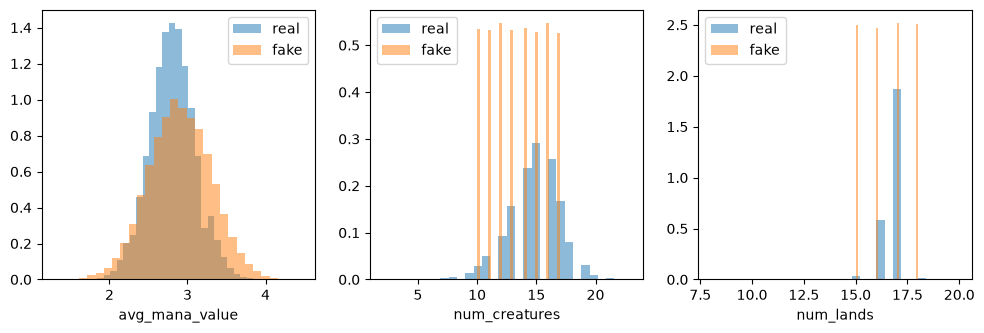

overall win rate: real 55.8 fake 46.7


In [13]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, col in zip(axes, ["avg_mana_value", "num_creatures", "num_lands"]):
    ax.hist(decks[col], bins=30, density=True, alpha=0.5, label="real")
    ax.hist(fake[col], bins=30, density=True, alpha=0.5, label="fake")
    ax.set_xlabel(col)
    ax.legend()
fig.savefig("fig/fake_vs_real.png", dpi=200, bbox_inches="tight")
plt.show()

print("overall win rate: real", round(100 * decks.wins.sum() / decks.games.sum(), 1),
      "fake", round(100 * fake.wins.sum() / fake.games.sum(), 1))

The fit finds the peaks we put in (mana value 2.9 and 17 lands) to within about 0.1 across 30 seeds, and the creature slope is inside its confidence interval. So the code can find a peak when there is one, which means the missing mana value peak in the real data is a real result and not a bug.

The fake decks are not very realistic. They have a lower win rate (46.7 vs 55.8), a wider spread in mana value and lands, and no colour pair effect. So this checks that the method works, not that the real effects are the ones we put in.

## Residuals and calibration

Plot the residuals against time or against the prediction, and say whether the error looks like noise or like bias. Check calibration on the held-out data. Say how the error grows as the forecast moves further from the data.


In [14]:
# one date per draft
dates = con.sql("SELECT draft_id, min(draft_time) AS draft_time FROM games GROUP BY draft_id").df()

res = test.merge(dates, on="draft_id", how="left")
res["pred"] = statsmodels_logit.predict(sm_fit, res)
res["rate"] = res.wins / res.games
res["resid"] = res.rate - res.pred  # actual - predicted
res["week"] = res.draft_time.dt.to_period("W").dt.start_time

print("decks with no date:", res.draft_time.isna().sum())

decks with no date: 0


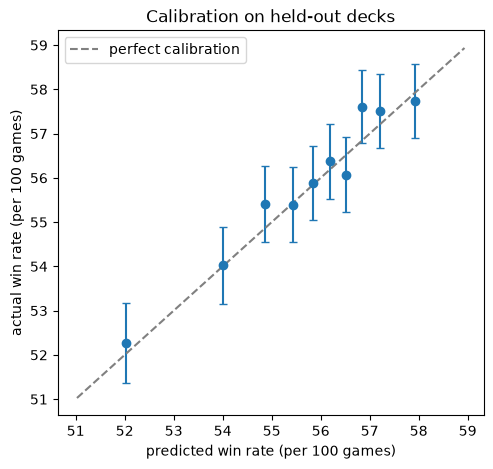

,pred,actual,games,ci
pred_bin,,,,
"(0.415, 0.533]",52.03,52.27,11854.0,0.90
"(0.533, 0.545]",54.01,54.03,12520.0,0.87
"(0.545, 0.552]",54.87,55.41,13060.0,0.85
"(0.552, 0.556]",55.42,55.39,13363.0,0.84
"(0.556, 0.56]",55.84,55.88,13377.0,0.84
"(0.56, 0.564]",56.19,56.37,13370.0,0.84
"(0.564, 0.567]",56.51,56.08,13448.0,0.84
"(0.567, 0.57]",56.84,57.61,13707.0,0.83
"(0.57, 0.575]",57.22,57.51,13577.0,0.83


In [15]:
# calibration: 10 groups by predicted win rate, predicted vs actual
res["pred_bin"] = pd.qcut(res.pred, 10)
cal = res.groupby("pred_bin", observed=True).apply(
    lambda d: pd.Series({"pred": 100 * np.average(d.pred, weights=d.games),
                         "actual": 100 * d.wins.sum() / d.games.sum(),
                         "games": d.games.sum()}), include_groups=False)
cal["ci"] = 196 * np.sqrt(cal.actual / 100 * (1 - cal.actual / 100) / cal.games)  # 95% error bar

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.errorbar(cal.pred, cal.actual, yerr=cal.ci, fmt="o", capsize=3)
lim = [cal.pred.min() - 1, cal.pred.max() + 1]
ax.plot(lim, lim, "--", color="gray", label="perfect calibration")
ax.set_xlabel("predicted win rate (per 100 games)")
ax.set_ylabel("actual win rate (per 100 games)")
ax.set_title("Calibration on held-out decks")
ax.legend()
fig.savefig("fig/calibration.png", dpi=200, bbox_inches="tight")
plt.show()
cal.round(2)

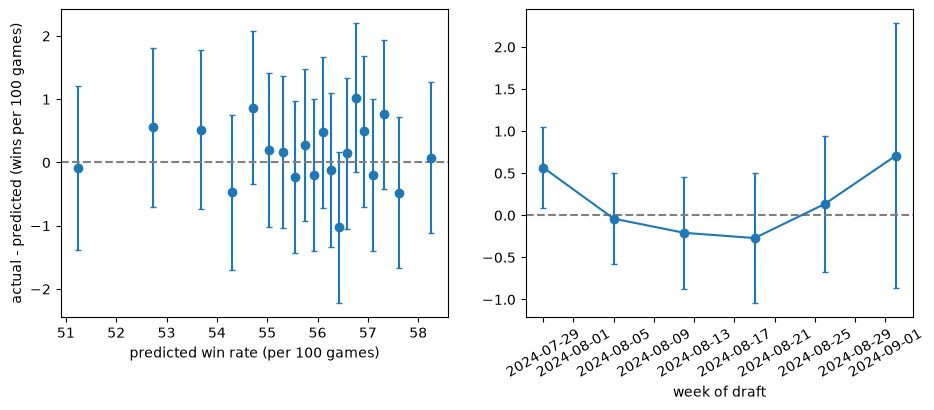

,resid,games,ci
week,,,
2024-07-29,0.57,42039.0,0.48
2024-08-05,-0.04,33303.0,0.54
2024-08-12,-0.21,21885.0,0.66
2024-08-19,-0.27,15959.0,0.78
2024-08-26,0.14,14711.0,0.81
2024-09-02,0.71,3872.0,1.57


In [16]:
def pooled(d):
    # average residual weighted by games, in wins per 100
    return pd.Series({"resid": 100 * np.average(d.resid, weights=d.games), "games": d.games.sum()})

res["pred_bin"] = pd.qcut(res.pred, 20)
by_pred = res.groupby("pred_bin", observed=True).apply(pooled, include_groups=False)
by_pred["x"] = res.groupby("pred_bin", observed=True).pred.mean() * 100
by_week = res.groupby("week").apply(pooled, include_groups=False)
# 95% error bar for a win rate near 50%
by_pred["ci"] = 196 * np.sqrt(0.25 / by_pred.games)
by_week["ci"] = 196 * np.sqrt(0.25 / by_week.games)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].errorbar(by_pred.x, by_pred.resid, yerr=by_pred.ci, fmt="o", capsize=2)
axes[0].axhline(0, color="gray", ls="--")
axes[0].set_xlabel("predicted win rate (per 100 games)")
axes[0].set_ylabel("actual - predicted (wins per 100 games)")
axes[1].errorbar(by_week.index, by_week.resid, yerr=by_week.ci, fmt="o-", capsize=2)
axes[1].axhline(0, color="gray", ls="--")
axes[1].set_xlabel("week of draft")
axes[1].tick_params(axis="x", rotation=30)
fig.savefig("fig/residuals.png", dpi=200, bbox_inches="tight")
plt.show()
by_week.round(2)

In [17]:
# bias and error by mana value bin, to see what happens at the edges
edges = [0, 2.2, 2.5, 2.8, 3.1, 3.4, 6]
res["m_bin"] = pd.cut(res.avg_mana_value, edges)
edge = res.groupby("m_bin", observed=True).apply(
    lambda d: pd.Series({"test_decks": len(d),
                         "bias": 100 * np.average(d.resid, weights=d.games),
                         "error": error_per_100(d, d.pred)}), include_groups=False)
edge["train_decks"] = pd.cut(train.avg_mana_value, edges).value_counts().sort_index().values
edge.round(2)

,test_decks,bias,error,train_decks
m_bin,,,,
"(0.0, 2.2]",421.0,0.70,16.64,1326
"(2.2, 2.5]",3526.0,0.25,17.82,10572
"(2.5, 2.8]",9296.0,0.06,17.17,28065
"(2.8, 3.1]",9449.0,0.03,17.27,28293
"(3.1, 3.4]",3345.0,0.33,18.14,10330
"(3.4, 6.0]",599.0,1.16,17.99,1678


Calibration: when the model says about 52%, about 52% of the held-out games are won, and the same at 58%. All ten groups are inside their error bars so the model is well calibrated.

Residuals: there is no trend against the prediction. Against time they stay under 1 win per 100 games and look like noise, a little higher in the first and last weeks.

Away from the middle: the error on a single deck is about 17 to 18 wins per 100 games everywhere, because a few games per deck is mostly luck. What changes at the edges is the bias. It is close to 0 for normal decks (mana value 2.5 to 3.1) and grows to +0.7 and +1.2 for the cheapest and most expensive decks, where there are only 1,300 to 1,700 training decks. So the model slightly underestimates those decks. Those two bins only have 421 and 599 test decks so this is within noise, but it is the direction to watch.

## Decision

Turn the prediction into an action with an explicit rule, and say why the loss picks it. Show how the action moves when the main input changes, and what it would be worth to be less wrong, in the units of the loss.


In [18]:
from models.common import follows_advice, value_per_100

# best value for each deck choice, only looking at values real decks use
best = statsmodels_logit.best_values(sm_fit, train)
colour = statsmodels_logit.best_colour(sm_fit, train)

for col, b in best.items():
    print(col, "best:", b["best"], "|", b["shape"], "| predicted", round(max(b["wins_per_100"]), 1), "at best")
print("colour pair:", colour["best"], "vs runner-up", colour["runner_up"], "p =", round(colour["p_vs_runner_up"], 2))

# what the advice is worth on the test decks
follows = follows_advice(test, best, train)
value = value_per_100(test, follows)
print()
print("follow the advice:", round(value["follows_advice"], 1), "wins per 100,", value["n_follow"], "decks")
print("played 17 lands:", round(value["baseline"], 1), "wins per 100,", value["n_base"], "decks")
print("gain:", round(value["gain"], 2), "wins per 100 games")

avg_mana_value best: 2.2 | lower is better | predicted 57.1 at best
num_creatures best: 19.0 | higher is better | predicted 57.1 at best
num_lands best: 16.0 | peak | predicted 56.1 at best
colour pair: BG vs runner-up WG p = 0.24

follow the advice: 57.3 wins per 100, 1056 decks
played 17 lands: 55.6 wins per 100, 19869 decks
gain: 1.73 wins per 100 games


In [19]:
rows = []
# does the best value change if we need more or fewer decks at a value
for md in [100, 500, 2000]:
    row = {"min_decks": md}
    for col, step in statsmodels_logit.STEPS.items():
        grid = statsmodels_logit.data_grid(train, col, step, min_decks=md)
        w = statsmodels_logit.curve(sm_fit, train, col, grid)
        row[col] = grid[int(np.argmax(w))]
    rows.append(row)
pd.DataFrame(rows)

,min_decks,avg_mana_value,num_creatures,num_lands
0,100,2.0,21.0,16.0
1,500,2.2,19.0,16.0
2,2000,2.3,18.0,16.0


In [20]:
# bootstrap the best values, 20 refits
rng = np.random.default_rng(SEED)
draft_ids = train.draft_id.unique()
rows = []
for i in range(20):
    drawn = pd.DataFrame({"draft_id": rng.choice(draft_ids, size=len(draft_ids), replace=True)})
    resampled = drawn.merge(train[keep], on="draft_id")
    b = statsmodels_logit.best_values(statsmodels_logit.fit(resampled), resampled)
    rows.append({col: b[col]["best"] for col in b})
    del drawn, resampled
    gc.collect()
    if (i + 1) % 5 == 0:
        print(f"{i + 1}/20 done")
boot_best = pd.DataFrame(rows)
boot_best.apply(lambda s: s.value_counts()).fillna(0).astype(int)

5/20 done
10/20 done
15/20 done
20/20 done


,avg_mana_value,num_creatures,num_lands
2.1,2,0,0
2.2,18,0,0
16.0,0,0,19
17.0,0,0,1
19.0,0,15,0
20.0,0,5,0


In [21]:
# refit on 25%, 50% and 100% of the training drafts to see what more data is worth
rng = np.random.default_rng(SEED)
all_ids = train.draft_id.unique()
rows = []
for frac in [0.25, 0.5, 1.0]:
    for rep in range(3 if frac < 1 else 1):
        ids = rng.choice(all_ids, size=int(frac * len(all_ids)), replace=False)
        sub = train[train.draft_id.isin(ids)]
        f = statsmodels_logit.fit(sub)
        b = statsmodels_logit.best_values(f, sub)
        v = value_per_100(test, follows_advice(test, b, sub))
        rows.append({"fraction": frac, "train_decks": len(sub),
                     "error": error_per_100(test, statsmodels_logit.predict(f, test)),
                     "gain": v["gain"]})
lc = pd.DataFrame(rows)
lc.groupby("fraction")[["error", "gain"]].agg(["mean", "std"]).round(3)

error          gain       
            mean    std   mean    std
fraction                             
0.25      17.428  0.005  1.706  0.000
0.50      17.422  0.003  1.774  0.118
1.00      17.419    NaN  1.729    NaN

The rule: build toward the highest predicted win chance, only using values real decks use.
- Lands: 16. This is a real peak, 15 and 17 are both worse.
- Average mana value: as low as your pool allows (lowest seen in real decks: 2.2). There is no sweet spot in the middle.
- Creatures: as many as your pool allows (most seen: 19).
- Colour pair: BG or WG. They are too close to separate (p = 0.24).

If two builds are possible, play the one with the higher predicted win chance.

Why the loss picks this: the loss is 1 - p, the chance of losing the game. It is smallest when p is largest, so the best build is the one with the highest predicted p. Premier Draft is best-of-1 so one game is one match.

What it is worth: decks that followed the advice won 57.3 per 100 games and decks that played 17 lands won 55.6, so +1.7 wins per 100 games (1,056 decks against 19,869).

What less error is worth: almost nothing. Four times the training data lowers the held-out error by 0.009 wins per 100 and the advice doesn't change. Most of the error is luck in the few games each deck plays.

## Limits

Where the model should not be trusted, what was assumed, and what you would do with more time or data. State the key effects in plain language and in real units.


Effects in real units (predicted wins per 100 games, for a two-colour BLB Premier Draft deck):
- Lands: 16 is best, about 1 to 1.5 wins per 100 better than 15 or 17. Held-out decks on 16 lands won about 56.9 against 55.6 on 17.
- Average mana value: lower is better. Going from 2.2 to 3.4 costs about 2.8 wins per 100, or about 0.25 per 0.1 of mana value. There is no sweet spot in the middle.
- Creatures: more is better, up to 19 which is the most real decks use here.
- All together: decks that followed the advice won about 1.7 more games per 100 than 17 land decks (57.3 against 55.6).

Where not to trust the model:
- Single decks. A deck plays about 5 games so its win rate is mostly luck. The error on one deck is about 17 wins per 100, barely better than guessing the average (17.49). Use the model for the shape of the curves, not for predicting one deck.
- Decks unlike the ones in the data. Fewer than about 1,700 training decks have a mana value above 3.4 or below 2.2, and the model underestimates them a little (0.7 to 1.2 wins per 100). "Lower is better" and "more is better" are at the edge of the data, so they mean as far as real decks go, not a tested best value.
- Anything else. We only looked at Bloomburrow, Premier Draft, best-of-1, two-colour decks with no splash, from 30 July to 3 September 2024 (the first five weeks of the set).
- Colour pair. BG and WG can't be told apart (p = 0.24) so we don't claim a best pair.

What we assumed:
- Players chose their decks, this is not an experiment. Strong decks may also be cheap and creature heavy, so some of the effect could be card quality. The model can't separate them. This is the assumption we trust least.
- Games from the same deck and drafts from the same player are treated as independent, so the error bars are a bit too narrow.
- Each input is a quadratic curve and the effects add up on the log-odds scale, with no interactions (for example between lands and creatures). Mana value and its square are almost perfectly correlated (0.997) so their coefficients can't be read one at a time.
- 17lands users chose to install a tracker, so they are probably better than the average player.
- Player skill is not in the cleaned table. We also don't know which cards were played and which were in the sideboard, so mana value and creature count are for the whole build.
- The split is random, not by date, so we haven't tested if the pattern holds later in the season. Residuals by week looked like noise (all under 1 win per 100).

With more time or data we would:
- add a card quality measure, to compare decks of similar strength
- add player skill and give advice per skill level
- split by date
- test other sets and best-of-3
- look at whether the trees or neural network from the slides find interactions that change the advice

More data alone would not help: four times the training data lowered the held-out error by only 0.009 wins per 100 and the advice stayed the same.